# Predicting March Madness Success
**CPSC 4300 Course Project (reconstruction)** · Cole DiGregorio

Can a team's adjusted offensive and defensive efficiency predict how far it advances in the NCAA
Division I men's basketball tournament? Tournament teams from 2003–2024 (no tournament in 2020).

Data: *March Madness Historical Dataset* by Jonathan Pilafas on Kaggle (KenPom metrics, MIT license),
version 31. See `docs/RECONSTRUCTION.md` for what was recovered vs. inferred.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## 1. Data cleaning
Load the Kaggle data and keep only the columns this study uses.

In [2]:
df = pd.read_csv("data/march_madness_kaggle_v31.csv")
print(df.shape)

df = df[["Season", "Mapped ESPN Team Name",
         "Adjusted Offensive Efficiency", "Adjusted Defensive Efficiency",
         "Post-Season Tournament", "Final Four?", "Tournament Winner?"]]
df = df.rename(columns={"Mapped ESPN Team Name": "Team",
                        "Adjusted Offensive Efficiency": "AdjOE",
                        "Adjusted Defensive Efficiency": "AdjDE"})
df.head()

(8680, 179)


,Season,Team,AdjOE,AdjDE,Post-Season Tournament,Final Four?,Tournament Winner?
0,2025,Duke,130.1,90.8,March Madness,No,No
1,2026,Duke,128.0,89.1,March Madness,No,No
2,2026,Arizona,127.7,90.0,March Madness,No,No
3,2026,Michigan,126.6,89.0,March Madness,No,No
4,2015,Kentucky,121.3,84.4,March Madness,Yes,No


Keep the study years, 2003–2024. The 2020 tournament was cancelled (COVID-19).

In [3]:
years = [y for y in range(2003, 2025) if y != 2020]
df = df[df["Season"].isin(years)]
print(len(years), "tournaments,", len(df), "team-seasons (all of Division I)")

21 tournaments, 7271 team-seasons (all of Division I)


Build a list of every tournament team for each year, then remove any team not in the list for its year.

In [4]:
tourney_teams = (df[df["Post-Season Tournament"] == "March Madness"]
                 .groupby("Season")["Team"].apply(set).to_dict())

tourney = df[df.apply(lambda row: row["Team"] in tourney_teams[row["Season"]], axis=1)]
tourney = tourney.drop_duplicates(subset=["Season", "Team"]).reset_index(drop=True)

print(len(tourney), "tournament team-seasons")
print(tourney.groupby("Season").size().to_dict())
print("Missing values:", tourney[["AdjOE", "AdjDE"]].isna().sum().sum())

1402 tournament team-seasons
{2003: 65, 2004: 65, 2005: 65, 2006: 65, 2007: 65, 2008: 65, 2009: 65, 2010: 65, 2011: 68, 2012: 68, 2013: 68, 2014: 68, 2015: 67, 2016: 68, 2017: 68, 2018: 68, 2019: 68, 2021: 68, 2022: 68, 2023: 67, 2024: 68}
Missing values: 0


A separate data frame holds the sets of Elite Eight teams, Final Four teams, and champions for each year.
Final Four and champions come from the dataset's flags. Elite Eight is not in the dataset, so it was
compiled by hand in `data/elite_eight.csv` (checked against Sports-Reference brackets).

In [5]:
elite_eight = pd.read_csv("data/elite_eight.csv")

results = pd.DataFrame({
    "Elite Eight": elite_eight.groupby("Season")["Team"].apply(set),
    "Final Four":  tourney[tourney["Final Four?"] == "Yes"].groupby("Season")["Team"].apply(set),
    "Champion":    tourney[tourney["Tournament Winner?"] == "Yes"].groupby("Season")["Team"].apply(set),
})
results.head()

,Elite Eight,Final Four,Champion
Season,,,
2003,"{Arizona, Marquette, Syracuse, Kansas, Michiga...","{Marquette, Texas, Kansas, Syracuse}",{Syracuse}
2004,"{Xavier, Saint Joseph's, Oklahoma State, UConn...","{Duke, Georgia Tech, UConn, Oklahoma State}",{UConn}
2005,"{Arizona, Michigan State, Illinois, North Caro...","{Michigan State, Illinois, North Carolina, Lou...",{North Carolina}
2006,"{George Mason, UConn, Memphis, UCLA, Florida, ...","{UCLA, Florida, George Mason, LSU}",{Florida}
2007,"{Memphis, UCLA, Florida, North Carolina, Kansa...","{UCLA, Florida, Ohio State, Georgetown}",{Florida}


In [6]:
# 1/0 target columns: did this team reach each round?
for col in ["Elite Eight", "Final Four", "Champion"]:
    tourney[col] = tourney.apply(lambda row: int(row["Team"] in results.loc[row["Season"], col]), axis=1)

print(tourney[["Elite Eight", "Final Four", "Champion"]].sum().to_dict())

# sanity checks: every Final Four team is an Elite Eight team, every champion a Final Four team
assert (tourney["Final Four"] <= tourney["Elite Eight"]).all()
assert (tourney["Champion"] <= tourney["Final Four"]).all()

{'Elite Eight': 168, 'Final Four': 84, 'Champion': 21}


## 2. K-Means clustering
Group tournament teams into 3 clusters using **only** adjusted offensive and defensive efficiency.
Tournament outcomes are not used to fit the clusters.

In [7]:
X = tourney[["AdjOE", "AdjDE"]]
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
raw_labels = kmeans.fit_predict(X)

# K-Means numbers its clusters arbitrarily. Renumber them by net efficiency (AdjOE - AdjDE) of each
# cluster center so the numbering is stable: 0 = weakest, 2 = strongest. Uses only the centers.
centers = pd.DataFrame(kmeans.cluster_centers_, columns=["AdjOE", "AdjDE"])
order = (centers["AdjOE"] - centers["AdjDE"]).sort_values().index
mapping = {old: new for new, old in enumerate(order)}
tourney["Cluster"] = pd.Series(raw_labels).map(mapping)

centers.index = centers.index.map(mapping)
centers = centers.sort_index()
centers["Teams"] = tourney["Cluster"].value_counts().sort_index()
centers.round(1)

,AdjOE,AdjDE,Teams
0,105.0,102.9,339
1,110.8,93.0,568
2,117.3,97.0,495


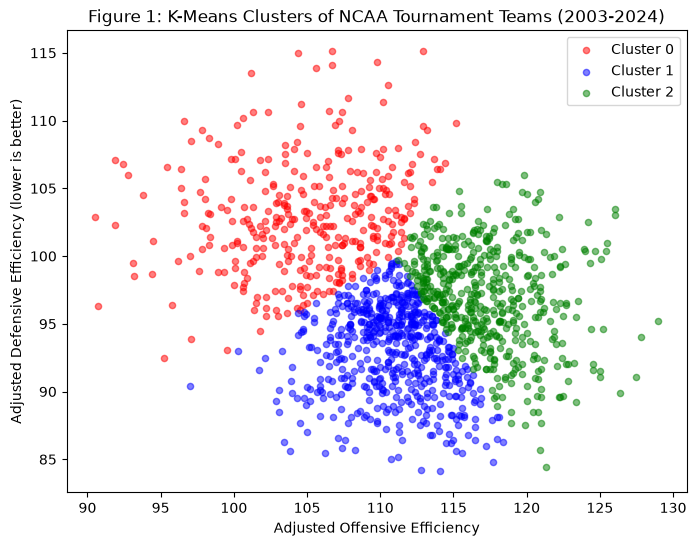

In [8]:
colors = {0: "red", 1: "blue", 2: "green"}

plt.figure(figsize=(8, 6))
for c in [0, 1, 2]:
    group = tourney[tourney["Cluster"] == c]
    plt.scatter(group["AdjOE"], group["AdjDE"], c=colors[c], alpha=0.5, s=20, label=f"Cluster {c}")
plt.xlabel("Adjusted Offensive Efficiency")
plt.ylabel("Adjusted Defensive Efficiency (lower is better)")
plt.title("Figure 1: K-Means Clusters of NCAA Tournament Teams (2003-2024)")
plt.legend()
plt.savefig("figures/figure1_clusters.png", dpi=150, bbox_inches="tight")
plt.show()

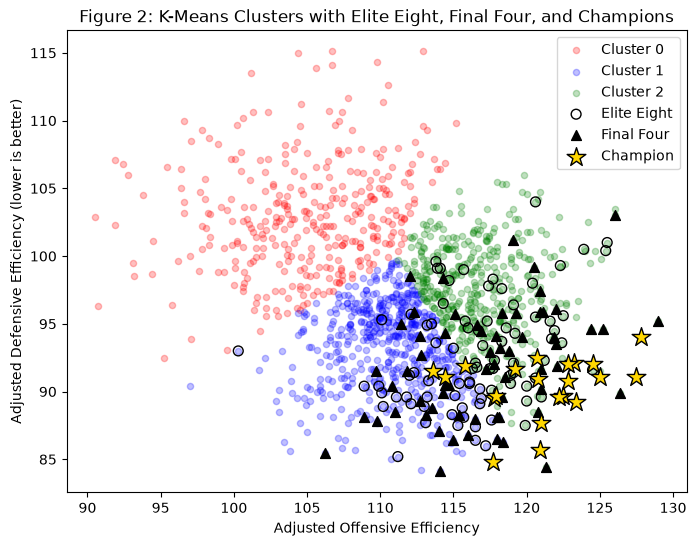

In [9]:
plt.figure(figsize=(8, 6))
for c in [0, 1, 2]:
    group = tourney[tourney["Cluster"] == c]
    plt.scatter(group["AdjOE"], group["AdjDE"], c=colors[c], alpha=0.25, s=20, label=f"Cluster {c}")

e8 = tourney[(tourney["Elite Eight"] == 1) & (tourney["Final Four"] == 0)]
f4 = tourney[(tourney["Final Four"] == 1) & (tourney["Champion"] == 0)]
ch = tourney[tourney["Champion"] == 1]
plt.scatter(e8["AdjOE"], e8["AdjDE"], facecolors="none", edgecolors="black", s=50, label="Elite Eight")
plt.scatter(f4["AdjOE"], f4["AdjDE"], marker="^", c="black", s=50, label="Final Four")
plt.scatter(ch["AdjOE"], ch["AdjDE"], marker="*", c="gold", edgecolors="black", s=200, label="Champion")
plt.xlabel("Adjusted Offensive Efficiency")
plt.ylabel("Adjusted Defensive Efficiency (lower is better)")
plt.title("Figure 2: K-Means Clusters with Elite Eight, Final Four, and Champions")
plt.legend()
plt.savefig("figures/figure2_clusters_overlay.png", dpi=150, bbox_inches="tight")
plt.show()

How are successful teams spread across the clusters? (Elite Eight includes the Final Four and
champions; Final Four includes champions.) The paper's original numbers are shown for comparison.

In [10]:
paper = {"Elite Eight": [0, 40.0, 60.0], "Final Four": [0, 39.8, 60.2], "Champion": [0, 38.1, 61.9]}

rows = []
for col in ["Elite Eight", "Final Four", "Champion"]:
    counts = tourney[tourney[col] == 1]["Cluster"].value_counts().reindex([0, 1, 2], fill_value=0)
    pct = counts / counts.sum() * 100
    for c in [0, 1, 2]:
        rows.append({"Round": col, "Cluster": c, "Teams": counts[c],
                     "Rebuilt %": round(pct[c], 1), "Original paper %": paper[col][c]})
distribution = pd.DataFrame(rows)
distribution

,Round,Cluster,Teams,Rebuilt %,Original paper %
0,Elite Eight,0,0,0.0,0.0
1,Elite Eight,1,68,40.5,40.0
2,Elite Eight,2,100,59.5,60.0
3,Final Four,0,0,0.0,0.0
4,Final Four,1,32,38.1,39.8
5,Final Four,2,52,61.9,60.2
6,Champion,0,0,0.0,0.0
7,Champion,1,4,19.0,38.1
8,Champion,2,17,81.0,61.9


## 3. Logistic regression
Three binary models (Elite Eight, Final Four, Champion), each with two features: AdjOE and AdjDE.
Each is trained on 80% of tournament teams and evaluated on the held-out 20%.

In [11]:
X = tourney[["AdjOE", "AdjDE"]]
paper_coefs = {"Elite Eight": (0.2981, -0.3063), "Final Four": (0.2990, -0.3166), "Champion": (0.4557, -0.4046)}

coef_rows = []
for target in ["Elite Eight", "Final Four", "Champion"]:
    y = tourney[target]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print("=" * 60)
    print(target, "| positives in test set:", y_test.sum(), "of", len(y_test))
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
    print("Confusion matrix [[TN FP] [FN TP]]:")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, zero_division=0))

    coef_rows.append({"Model": target,
                      "AdjOE coef": round(model.coef_[0][0], 4), "AdjDE coef": round(model.coef_[0][1], 4),
                      "Original paper AdjOE": paper_coefs[target][0], "Original paper AdjDE": paper_coefs[target][1]})

coefs = pd.DataFrame(coef_rows)
coefs

Elite Eight | positives in test set: 28 of 281
Accuracy: 0.893
Confusion matrix [[TN FP] [FN TP]]:
[[242  11]
 [ 19   9]]
              precision    recall  f1-score   support

           0       0.93      0.96      0.94       253
           1       0.45      0.32      0.38        28

    accuracy                           0.89       281
   macro avg       0.69      0.64      0.66       281
weighted avg       0.88      0.89      0.89       281

Final Four | positives in test set: 12 of 281
Accuracy: 0.943
Confusion matrix [[TN FP] [FN TP]]:
[[264   5]
 [ 11   1]]
              precision    recall  f1-score   support

           0       0.96      0.98      0.97       269
           1       0.17      0.08      0.11        12

    accuracy                           0.94       281
   macro avg       0.56      0.53      0.54       281
weighted avg       0.93      0.94      0.93       281

Champion | positives in test set: 1 of 281
Accuracy: 0.996
Confusion matrix [[TN FP] [FN TP]]:
[[280   

,Model,AdjOE coef,AdjDE coef,Original paper AdjOE,Original paper AdjDE
0,Elite Eight,0.3076,-0.3327,0.2981,-0.3063
1,Final Four,0.3114,-0.3524,0.2990,-0.3166
2,Champion,0.4444,-0.4079,0.4557,-0.4046


**Check (not part of the original project):** the original train/test split is unknown, so here is how much
the coefficients move across different random splits. This helps judge how far the rebuilt
coefficients could reasonably be from the paper's.

In [12]:
spread = []
for target in ["Elite Eight", "Final Four", "Champion"]:
    for seed in range(50):
        X_train, X_test, y_train, y_test = train_test_split(X, tourney[target], test_size=0.2, random_state=seed)
        m = LogisticRegression(max_iter=1000).fit(X_train, y_train)
        spread.append({"Model": target, "AdjOE coef": m.coef_[0][0], "AdjDE coef": m.coef_[0][1]})
pd.DataFrame(spread).groupby("Model", sort=False).agg(["min", "median", "max"]).round(3)

AdjOE coef               AdjDE coef              
                   min median    max        min median    max
Model                                                        
Elite Eight      0.285  0.307  0.333     -0.333 -0.301 -0.266
Final Four       0.251  0.296  0.336     -0.362 -0.299 -0.264
Champion         0.342  0.461  0.684     -0.604 -0.404 -0.353

In [13]:
# Example: predicted probabilities for the 2024 champion and a few other 2024 teams
example = tourney[tourney["Season"] == 2024].copy()
for target in ["Elite Eight", "Final Four", "Champion"]:
    X_train, X_test, y_train, y_test = train_test_split(X, tourney[target], test_size=0.2, random_state=42)
    m = LogisticRegression(max_iter=1000).fit(X_train, y_train)
    example["P(" + target + ")"] = m.predict_proba(example[["AdjOE", "AdjDE"]])[:, 1].round(3)
example.sort_values("P(Champion)", ascending=False).head(8)[
    ["Team", "AdjOE", "AdjDE", "Cluster", "Champion", "P(Elite Eight)", "P(Final Four)", "P(Champion)"]]

,Team,AdjOE,AdjDE,Cluster,Champion,P(Elite Eight),P(Final Four),P(Champion)
2,UConn,127.5,91.1,2,1,0.954,0.879,0.779
24,Houston,118.9,87.7,2,0,0.820,0.624,0.236
31,Purdue,125.2,94.6,2,0,0.761,0.509,0.233
65,Auburn,120.4,92.4,2,0,0.602,0.336,0.081
106,Duke,121.6,95.2,2,0,0.463,0.215,0.046
104,Arizona,120.2,93.7,2,0,0.480,0.231,0.045
102,Tennessee,116.8,90.2,1,0,0.510,0.263,0.042
109,North Carolina,119.7,93.5,2,0,0.458,0.216,0.040


## 4. Findings (rebuilt run vs. original paper)

| | Rebuilt | Original paper |
|---|---|---|
| Elite Eight in Cluster 1 / 2 | 40.5% / 59.5% | 40% / 60% |
| Final Four in Cluster 1 / 2 | 38.1% / 61.9% | 39.8% / 60.2% |
| Champions in Cluster 1 / 2 | 19.0% / 81.0% | 38.1% / 61.9% |
| Successful teams in Cluster 0 | 0 | 0 |
| Elite Eight coef (AdjOE / AdjDE) | +0.3076 / −0.3327 | +0.2981 / −0.3063 |
| Final Four coef | +0.3114 / −0.3524 | +0.2990 / −0.3166 |
| Champion coef | +0.4444 / −0.4079 | +0.4557 / −0.4046 |

- **No team in the low-efficiency Cluster 0 reached the Elite Eight** from 2003–2024, matching the original study.
- About 60% of Elite Eight and Final Four teams fall in Cluster 2, matching the original study. For champions
  the rebuilt run is more lopsided than the paper: 17 of 21 champions are in Cluster 2, not 13.
- Cluster profiles: Cluster 0 is low offense / weak defense; Cluster 1 is moderate offense / the best average
  defense; Cluster 2 is the highest offense with defense in between. In this run Cluster 2's *average*
  defense is not the strongest, which differs slightly from the paper's description.
- All three logistic models give a positive offensive and a negative defensive coefficient: higher offense and
  lower points allowed both raise the odds of a deep run. The paper's coefficients fall inside the range
  produced by different random train/test splits (see the check above).
- Accuracy looks high (0.89 / 0.94 / 0.996) only because most teams don't advance. The models catch few
  actual successful teams (Elite Eight recall 0.32, Final Four 0.08, Champion 0/1). This matches the
  original paper's conclusion that the models struggled with the rare successful teams.

**Limitations** (from the original paper): K-Means assumes round clusters and ignores outcomes; binary targets
ignore matchups and seeding; logistic regression assumes linear log odds; there are few positive examples.
**Added in the reconstruction:** the efficiency numbers are end-of-season, so they include tournament games,
which slightly favors teams that went deep.